# 06 — Backtest de la regla de alerta y KPIs

**Capa 7 — KPIs** · Backtest de la regla v1

**Pregunta:** si el comité hubiera seguido el semáforo, ¿habría reducido la caída máxima de la cartera frente a no hacer nada?

### La regla (fijada antes de ver los resultados; no se ajusta según el backtest)

| Semáforo de la semana *t* | Exposición objetivo |
|---|---|
| 🔴 Rojo | 50% |
| 🟢 Verde | 100% |
| 🟡 Amarillo | Mantiene la exposición anterior |

- **Calendario realista:** la señal se calcula con el cierre del viernes *t*. El comité la revisa y la orden se ejecuta al cierre de la semana *t+1*. La nueva exposición rige desde el retorno de la semana *t+2*. Así nunca se usa información que el comité aún no tendría.
- **Parte no invertida:** rinde 0%. Es un supuesto conservador: en la práctica podría estar en caja o renta fija y rendir algo.
- **Costos:** 0% en el caso base; sensibilidad con 0,1% del monto transado (pasar de 100% a 50% transa la mitad de la cartera y cuesta 0,05% de su valor).
- **Semáforo:** BSADF en ventana móvil de 260 semanas con persistencia de 6 semanas (notebook 03b).

### Dos carteras, por el sesgo de supervivencia

- **A) Nasdaq Composite (^IXIC)** con su propio semáforo, desde la primera semana con señal (historia desde 1990). Es la validación principal, porque un índice no tiene sesgo de supervivencia.
- **B) Las 9 acciones del universo con igual peso, desde 2018.** Cada acción sigue su propio semáforo y la cartera se rebalancea cada semana. **Advertencia:** son "ganadoras" conocidas de antemano (por eso están en el universo). Su retorno no es representativo de lo que se habría elegido en 2018, y el resultado debe leerse solo como comparación *entre* la regla y mantener las mismas acciones.

### Control placebo
Se compara la regla contra **1.000 reglas aleatorias** que reducen la exposición al 50% **el mismo número de episodios, con las mismas duraciones**, pero en fechas al azar. Si la regla real no supera a las aleatorias, su beneficio viene de *estar menos invertida*, no de *saber cuándo*.

La lógica vive en `src/backtest.py`.

In [1]:
import sys
import logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src import config as C
from src import ingesta as I
from src import features as F
from src import backtest as B

logging.basicConfig(level=logging.WARNING, format="%(levelname)-8s %(name)s | %(message)s",
                    stream=sys.stdout, force=True)
pd.set_option("display.width", 200)

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})
AZUL, NARANJA, GRIS, ROJO = "#2a78d6", "#eb6834", "#52514e", "#d03b3b"

FORMATO = {"caida_maxima": "{:.1%}", "retorno_anual": "{:.1%}", "volatilidad_anual": "{:.1%}",
           "sharpe": "{:.2f}", "retorno_total": "{:.0%}", "cambios_exposicion": "{:.0f}",
           "pct_tiempo_reducida": "{:.1%}"}
def mostrar(tabla):
    # Formatea una tabla de métricas (filas = métricas)
    return tabla.apply(lambda fila: fila.map(lambda v: FORMATO.get(fila.name, "{}").format(v)), axis=1)

## 1. Cartera A: datos de ^IXIC desde 1990

Se descarga ^IXIC desde 1990 hasta hoy con la misma función de ingesta y las mismas validaciones del universo. El archivo se guarda en `data/raw/IXIC_desde_1990.csv` y, si ya existe, se lee desde disco para que el backtest sea reproducible.

**¿Por qué desde 1990?** El BSADF necesita 260 semanas de historia antes de emitir su primera señal. Con datos desde 1990 el semáforo del Nasdaq existe desde fines de 1994 y cubre completa la subida de la puntocom (notebook 03b, sección 4).

In [2]:
RUTA_A = C.DIR_RAW / "IXIC_desde_1990.csv"
if RUTA_A.exists():
    crudo_a = pd.read_csv(RUTA_A, parse_dates=["fecha"])
else:
    crudo_a = I.descargar(["^IXIC"], inicio="1990-01-01")
    crudo_a.to_csv(RUTA_A, index=False)

validado_a, resumen_a, _ = I.validar_universo(crudo_a, ["^IXIC"])
print(resumen_a[["ticker", "n_dias", "fecha_inicio", "fecha_fin", "valida"]].to_string(index=False))

semanal_a = F.a_semanal(validado_a)
senales_a = F.senales_bsadf(semanal_a).set_index("fecha")
precio_a = semanal_a["^IXIC"]
colores_a = senales_a["semaforo"]

exposicion_a = B.exposicion_efectiva(B.exposicion_objetivo(colores_a))
inicio_a = colores_a.index[0]
retornos_a = precio_a.pct_change().loc[inicio_a:].iloc[1:]
exposicion_a = exposicion_a.reindex(retornos_a.index)
print(f"\nPeriodo evaluado: {retornos_a.index[0]:%d-%m-%Y} a {retornos_a.index[-1]:%d-%m-%Y} ({len(retornos_a)} semanas)")

ticker  n_dias fecha_inicio  fecha_fin  valida
 ^IXIC    9276   1990-01-02 2026-10-30    True



Periodo evaluado: 30-12-1994 a 30-10-2026 (1662 semanas)


## 2. Cartera A: periodo completo

In [3]:
tabla_a, regla_a = B.comparar(retornos_a, exposicion_a)
tabla_a_costo, _ = B.comparar(retornos_a, exposicion_a, costo=0.001)
tabla = pd.concat({"Costo 0% (base)": tabla_a, "Costo 0,1%": tabla_a_costo}, axis=1)
mostrar(tabla)

Costo 0% (base)               Costo 0,1%              
                              Regla Mantener 100%      Regla Mantener 100%
caida_maxima                 -73.2%        -77.4%     -73.2%        -77.4%
retorno_anual                 12.1%         11.7%      12.1%         11.7%
volatilidad_anual             21.5%         22.5%      21.4%         22.5%
sharpe                         0.64          0.61       0.64          0.61
retorno_total                 3730%         3327%      3716%         3327%
cambios_exposicion                8             0          8             0
pct_tiempo_reducida            7.4%          0.0%       7.4%          0.0%

**Cómo leerlo:**
- **Caída máxima:** la peor pérdida desde un máximo previo. Con la regla es menor que sin ella, pero solo algunos puntos porcentuales: la caída máxima del periodo es la de 2000-2002 y la regla la suaviza sin evitarla (sección 3).
- **Retorno anual, volatilidad y Sharpe:** la regla no sacrifica retorno en el periodo completo y reduce algo la volatilidad.
- **Cambios de exposición y % del tiempo reducida:** la regla actúa pocas veces y la mayor parte del tiempo está 100% invertida. Esto es consecuencia de la persistencia de 6 semanas.
- **Costos:** con 0,1% por monto transado el resultado casi no cambia, porque hay muy pocos cambios.

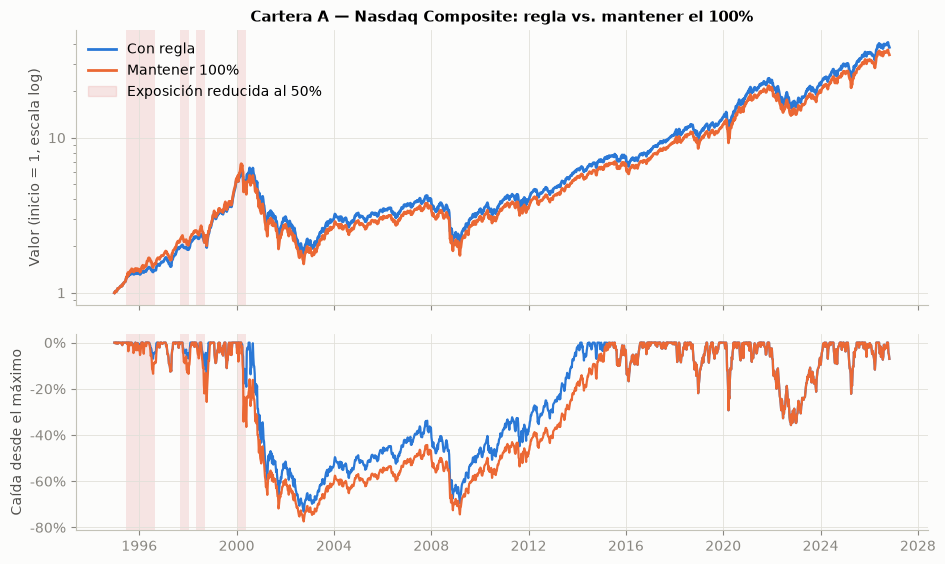

In [4]:
def franjas_reducida(ax, exposicion):
    # Sombrea las semanas con exposición reducida
    reducida = exposicion < 1
    grupos = (reducida != reducida.shift()).cumsum()[reducida]
    for _, g in reducida[reducida].groupby(grupos):
        ax.axvspan(g.index[0] - pd.Timedelta(days=7), g.index[-1], color=ROJO, alpha=0.12, lw=0)

def grafico_valor_drawdown(retornos, regla, exposicion, titulo, paso_anios=4):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True,
                                   gridspec_kw={"height_ratios": [1.4, 1], "hspace": 0.12})
    for serie, nombre, color in ((B.valor_cartera(regla), "Con regla", AZUL),
                                 (B.valor_cartera(retornos), "Mantener 100%", NARANJA)):
        ax1.plot(serie.index, serie, color=color, lw=2, label=nombre)
    for serie, color in ((B.drawdown(regla), AZUL), (B.drawdown(retornos), NARANJA)):
        ax2.plot(serie.index, serie, color=color, lw=1.6)
    for ax in (ax1, ax2):
        franjas_reducida(ax, exposicion)
    ax1.set_yscale("log")
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
    ax1.set_ylabel("Valor (inicio = 1, escala log)")
    ax1.set_title(titulo)
    ax1.fill_between([], [], color=ROJO, alpha=0.12, label="Exposición reducida al 50%")
    ax1.legend(loc="upper left", frameon=False)
    ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax2.set_ylabel("Caída desde el máximo")
    ax2.xaxis.set_major_locator(mdates.YearLocator(paso_anios))
    ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    plt.show()

grafico_valor_drawdown(retornos_a, regla_a, exposicion_a, "Cartera A — Nasdaq Composite: regla vs. mantener el 100%")

**Cómo leer el gráfico:** arriba, el valor de 1 dólar invertido (escala logarítmica: la misma distancia vertical es el mismo % de cambio). Abajo, la caída desde el máximo previo: mientras más abajo, peor. Las franjas rojas marcan las semanas con exposición al 50%. Se ven los episodios de 1995-1998 (tramos explosivos locales que la regla trata como alerta) y el de 1999-2000.

## 3. Cartera A: tres episodios de caída

Las fechas se obtienen de los datos con una regla fija (`B.episodio`):
- **Peak:** máximo semanal del Nasdaq dentro de una ventana de búsqueda que contiene el techo de cada ciclo.
- **Valle:** mínimo posterior al peak. Es el punto donde se completa la caída.
- **Inicio de la evaluación:** 52 semanas antes del peak, para incluir la fase de alza: ahí debería encenderse la señal y ahí se paga el costo de reducir exposición antes de tiempo.

| Episodio | Búsqueda del peak | Búsqueda del valle | Por qué |
|---|---|---|---|
| 2000-2002 | 1999-2000 | hasta mediados de 2003 | Burbuja puntocom: el caso que el producto debe detectar |
| 2007-2009 | 2007 - mediados de 2008 | hasta fines de 2009 | Crisis financiera: caída por crédito, no por burbuja tecnológica (control) |
| 2021-2022 | 2021 - marzo de 2022 | hasta mediados de 2023 | Alza de tasas tras el ciclo tecnológico pospandemia |

In [5]:
DEFINICION_EPISODIOS = {
    "2000-2002": ("1999-01-01", "2000-12-31", "2003-06-30"),
    "2007-2009": ("2007-01-01", "2008-06-30", "2009-12-31"),
    "2021-2022": ("2021-01-01", "2022-03-31", "2023-06-30"),
}
episodios = {n: B.episodio(precio_a, *fechas) for n, fechas in DEFINICION_EPISODIOS.items()}

filas = []
for nombre, ep in episodios.items():
    r = retornos_a.loc[ep["inicio"]:ep["valle"]]
    tabla_ep, _ = B.comparar(r, exposicion_a)
    anticipacion = B.anticipacion_rojo(colores_a, ep["peak"])
    filas.append({
        "episodio": nombre, "inicio evaluación": ep["inicio"].date(), "peak": ep["peak"].date(),
        "valle": ep["valle"].date(), "caída del índice peak-valle": ep["caida_indice"],
        "caída máx. regla": tabla_ep.loc["caida_maxima", "Regla"],
        "caída máx. mantener": tabla_ep.loc["caida_maxima", "Mantener 100%"],
        "mejora (pp)": 100 * (tabla_ep.loc["caida_maxima", "Regla"] - tabla_ep.loc["caida_maxima", "Mantener 100%"]),
        "retorno regla": tabla_ep.loc["retorno_total", "Regla"],
        "retorno mantener": tabla_ep.loc["retorno_total", "Mantener 100%"],
        "% tiempo reducida": tabla_ep.loc["pct_tiempo_reducida", "Regla"],
        "semáforo en el peak": colores_a.loc[ep["peak"]],
        "anticipación del rojo (semanas)": anticipacion if anticipacion is not None else "sin señal",
    })
tabla_episodios = pd.DataFrame(filas).set_index("episodio")

empeora_todos = (tabla_episodios["mejora (pp)"] < 0).all()
print("¿La regla empeora la caída máxima en los tres episodios?", "SÍ → detenerse y reportar" if empeora_todos else "No")
tabla_episodios.style.format({"caída del índice peak-valle": "{:.1%}", "caída máx. regla": "{:.1%}",
                              "caída máx. mantener": "{:.1%}", "mejora (pp)": "{:+.1f}", "retorno regla": "{:.1%}",
                              "retorno mantener": "{:.1%}", "% tiempo reducida": "{:.1%}"})

¿La regla empeora la caída máxima en los tres episodios? No


,inicio evaluación,peak,valle,caída del índice peak-valle,caída máx. regla,caída máx. mantener,mejora (pp),retorno regla,retorno mantener,% tiempo reducida,semáforo en el peak,anticipación del rojo (semanas)
episodio,,,,,,,,,,,,
2000-2002,1999-03-12,2000-03-10,2002-10-04,-77.4%,-73.2%,-77.4%,+4.3,-44.0%,-51.2%,11.2%,rojo,11
2007-2009,2006-11-03,2007-11-02,2009-03-06,-54.0%,-54.0%,-54.0%,+0.0,-45.0%,-45.0%,0.0%,verde,sin señal
2021-2022,2020-11-20,2021-11-19,2022-10-14,-35.7%,-35.7%,-35.7%,+0.0,-12.7%,-12.7%,0.0%,verde,sin señal


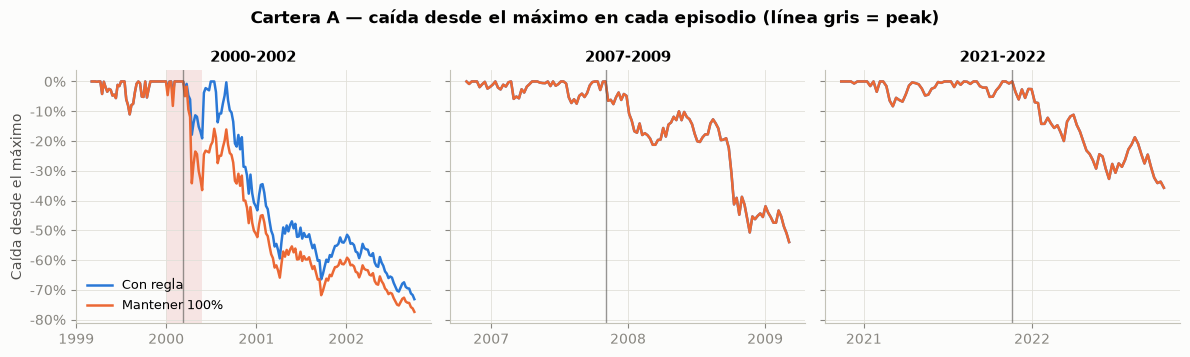

In [6]:
fig, ejes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, (nombre, ep) in zip(ejes, episodios.items()):
    r = retornos_a.loc[ep["inicio"]:ep["valle"]]
    regla = B.retornos_regla(r, exposicion_a)
    ax.plot(B.drawdown(regla).index, B.drawdown(regla), color=AZUL, lw=1.8, label="Con regla")
    ax.plot(B.drawdown(r).index, B.drawdown(r), color=NARANJA, lw=1.8, label="Mantener 100%")
    franjas_reducida(ax, exposicion_a.loc[r.index])
    ax.axvline(ep["peak"], color=GRIS, lw=1, alpha=0.6)
    ax.set_title(nombre)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ejes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ejes[0].set_ylabel("Caída desde el máximo")
ejes[0].legend(loc="lower left", frameon=False, fontsize=9)
fig.suptitle("Cartera A — caída desde el máximo en cada episodio (línea gris = peak)", fontweight="bold")
plt.tight_layout()
plt.show()

**Cómo leerlo:**
- **2000-2002:** la regla funciona como se diseñó al *inicio*. El rojo se enciende antes del peak (con persistencia de 6 semanas, ~11 semanas antes) y la cartera llega al peak con 50% de exposición. Pero cuando el BSADF baja tras el peak, el semáforo vuelve a verde y la regla **vuelve al 100% en mayo de 2000, en plena caída** (fin de la franja roja), con el índice ya 20-30% bajo su máximo. La mejora es real pero acotada: unos puntos porcentuales sobre una caída cercana al 78%.
- **2007-2009 y 2021-2022:** **no hubo señal**, así que la regla se comporta exactamente como mantener el 100%. Sin persistencia, la señal bruta marcó 7 semanas sueltas en rojo en la ventana 2007-2009; la regla de 6 semanas seguidas las filtró. Es lo esperable: el BSADF detecta crecimiento explosivo, no caídas. La crisis de 2008 no vino precedida de una burbuja en el Nasdaq, y el alza de 2020-2021 no fue lo bastante explosiva en el índice.
- **Conclusión del criterio de detención:** la regla **no empeora** la caída máxima en los tres episodios (la mejora en uno y la deja igual en dos). Se continúa con el plan.

## 4. Control placebo — cartera A

In [7]:
placebos_a = B.exposiciones_placebo(exposicion_a, n=1000)
r_np = retornos_a.to_numpy()
caidas_placebo_a = B.caida_maxima_matriz(placebos_a * r_np)
caida_real_a = tabla_a.loc["caida_maxima", "Regla"]

filas = [{"periodo": "Completo", "caída máx. regla": caida_real_a,
          "mediana placebo": np.median(caidas_placebo_a),
          "percentil placebo": B.percentil_placebo(caida_real_a, caidas_placebo_a)}]
for nombre, ep in episodios.items():
    tramo = (retornos_a.index >= ep["inicio"]) & (retornos_a.index <= ep["valle"])
    caidas = B.caida_maxima_matriz(placebos_a[:, tramo] * r_np[tramo])
    real = tabla_episodios.loc[nombre, "caída máx. regla"]
    actua = bool((exposicion_a[tramo] < 1).any())   # si la regla no actúa en la ventana, el percentil no aplica
    filas.append({"periodo": nombre, "caída máx. regla": real, "mediana placebo": np.median(caidas),
                  "percentil placebo": B.percentil_placebo(real, caidas) if actua else np.nan})
placebo_a = pd.DataFrame(filas).set_index("periodo")
print(f"Episodios de exposición reducida de la regla real: {len(B.episodios(exposicion_a < 1))} "
      f"(duraciones {[int(d) for d in B.episodios(exposicion_a < 1)]} semanas)")
placebo_a.style.format({"caída máx. regla": "{:.1%}", "mediana placebo": "{:.1%}", "percentil placebo": "{:.1f}"},
                       na_rep="no aplica")

Episodios de exposición reducida de la regla real: 4 (duraciones [61, 21, 20, 21] semanas)


,caída máx. regla,mediana placebo,percentil placebo
periodo,,,
Completo,-73.2%,-77.4%,14.4
2000-2002,-73.2%,-77.4%,15.2
2007-2009,-54.0%,-54.0%,no aplica
2021-2022,-35.7%,-35.7%,no aplica


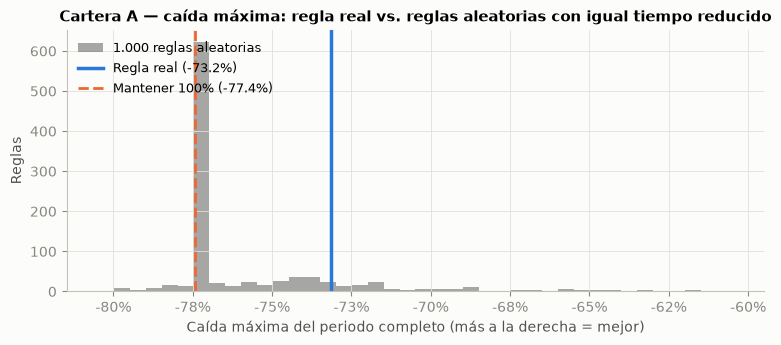

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(caidas_placebo_a, bins=40, color=GRIS, alpha=0.5, label="1.000 reglas aleatorias")
ax.axvline(caida_real_a, color=AZUL, lw=2.5, label=f"Regla real ({caida_real_a:.1%})")
ax.axvline(tabla_a.loc["caida_maxima", "Mantener 100%"], color=NARANJA, lw=2, ls="--",
           label=f"Mantener 100% ({tabla_a.loc['caida_maxima', 'Mantener 100%']:.1%})")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Caída máxima del periodo completo (más a la derecha = mejor)")
ax.set_ylabel("Reglas")
ax.set_title("Cartera A — caída máxima: regla real vs. reglas aleatorias con igual tiempo reducido")
ax.legend(frameon=False, fontsize=9, loc="upper left")
plt.show()

**Cómo leerlo:** el *percentil placebo* es el % de reglas aleatorias con una caída máxima **menos severa** que la regla real. Un percentil bajo (por ejemplo, 5) significa que la regla real supera al 95% de las aleatorias: la señal aporta. Un percentil cercano a 50 significa que la regla real no se distingue del azar.

En el periodo completo, **la regla real queda alrededor del percentil 14**: logra una caída máxima menos severa que ~86% de las reglas aleatorias con el mismo tiempo reducido. El *momento* de la señal aporta algo en el Nasdaq. Pero el beneficio es acotado, por la razón de la sección 3: el rojo llega a tiempo, pero la regla vuelve al 100% durante la caída.

> Los episodios placebo se ubican uniformemente al azar (`mascara_aleatoria`). La verificación independiente de estos percentiles está en `docs/auditoria.md`.

## 5. Cartera B: las 9 acciones con igual peso, desde 2018

> **Sesgo de supervivencia:** estas 9 acciones fueron elegidas en 2026 sabiendo que fueron ganadoras. El retorno absoluto de la cartera está inflado y no debe presentarse como rentabilidad alcanzable. Lo único comparable es la regla contra mantener **las mismas** acciones.

In [9]:
validados = pd.read_csv(C.DIR_PROCESSED / "precios_validados.csv", parse_dates=["fecha"])
panel = F.construir_panel(validados)
ACCIONES = list(C.UNIVERSO)
INICIO_B = pd.Timestamp("2018-01-05")

precios_b = panel.pivot(index="fecha", columns="ticker", values="adj_close")[ACCIONES]
colores_b = panel.pivot(index="fecha", columns="ticker", values="semaforo")[ACCIONES]
retornos_b = precios_b.pct_change().loc[INICIO_B:]
exposicion_b = pd.DataFrame({t: B.exposicion_efectiva(B.exposicion_objetivo(colores_b[t].dropna()))
                             for t in ACCIONES}).reindex(retornos_b.index)

regla_b, mantener_b = B.cartera_igual_peso(retornos_b, exposicion_b)
regla_b_costo, _ = B.cartera_igual_peso(retornos_b, exposicion_b, costo=0.001)
tabla_b = pd.concat({"Costo 0% (base)": B.metricas_cartera(regla_b, mantener_b, exposicion_b),
                     "Costo 0,1%": B.metricas_cartera(regla_b_costo, mantener_b, exposicion_b)}, axis=1)
print(f"Periodo: {retornos_b.index[0]:%d-%m-%Y} a {retornos_b.index[-1]:%d-%m-%Y} ({len(retornos_b)} semanas)")
mostrar(tabla_b)

Periodo: 05-01-2018 a 30-10-2026 (461 semanas)


Costo 0% (base)               Costo 0,1%              
                              Regla Mantener 100%      Regla Mantener 100%
caida_maxima                 -43.5%        -45.4%     -43.5%        -45.4%
retorno_anual                 33.6%         33.7%      33.6%         33.7%
volatilidad_anual             25.4%         27.1%      25.4%         27.1%
sharpe                         1.27          1.21       1.27          1.21
retorno_total                 1205%         1209%      1203%         1209%
cambios_exposicion               32             0         32             0
pct_tiempo_reducida           10.7%          0.0%      10.7%          0.0%

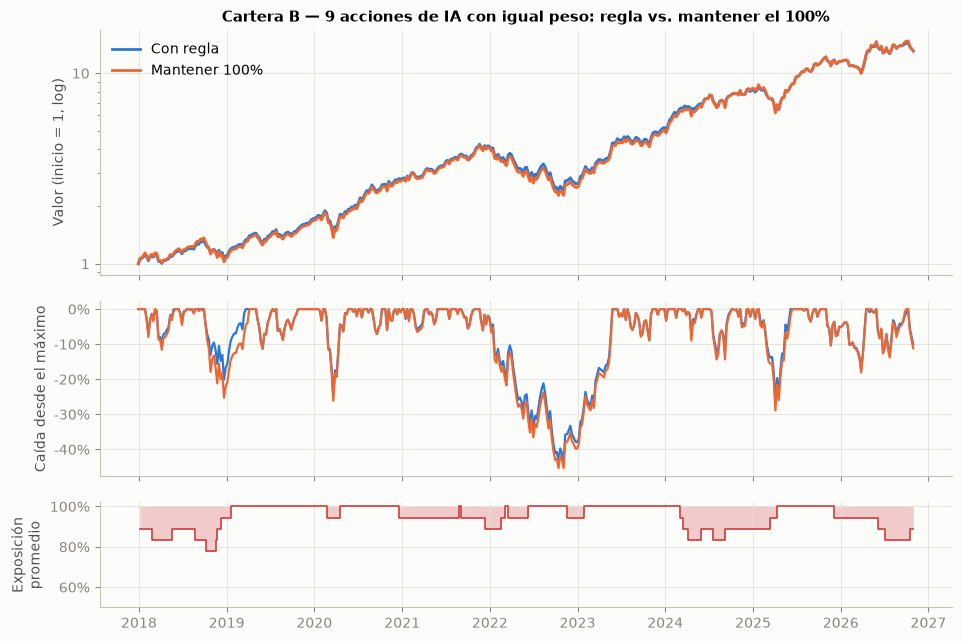

In [10]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True,
                                    gridspec_kw={"height_ratios": [1.4, 1, 0.6], "hspace": 0.15})
for serie, nombre, color in ((B.valor_cartera(regla_b), "Con regla", AZUL),
                             (B.valor_cartera(mantener_b), "Mantener 100%", NARANJA)):
    ax1.plot(serie.index, serie, color=color, lw=2, label=nombre)
for serie, color in ((B.drawdown(regla_b), AZUL), (B.drawdown(mantener_b), NARANJA)):
    ax2.plot(serie.index, serie, color=color, lw=1.6)
exposicion_promedio = exposicion_b.mean(axis=1)
ax3.fill_between(exposicion_promedio.index, exposicion_promedio, 1, color=ROJO, alpha=0.25, step="pre", lw=0)
ax3.step(exposicion_promedio.index, exposicion_promedio, color=ROJO, lw=1.2, where="pre")
ax1.set_yscale("log")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax1.set_ylabel("Valor (inicio = 1, log)")
ax1.set_title("Cartera B — 9 acciones de IA con igual peso: regla vs. mantener el 100%")
ax1.legend(loc="upper left", frameon=False)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax2.set_ylabel("Caída desde el máximo")
ax3.set_ylim(0.5, 1.02)
ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax3.set_ylabel("Exposición\npromedio")
ax3.xaxis.set_major_locator(mdates.YearLocator())
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()

**Cómo leer el gráfico:** el panel inferior muestra la exposición promedio de la cartera. Baja cuando una o más acciones están en rojo: cada acción en rojo resta 1/9 × 50% ≈ 5,6 puntos.

### Anticipación por acción
Para cada acción se identifica el peak previo a su mayor caída desde 2018 y se mide si hubo un rojo en las 52 semanas previas.

In [11]:
filas = []
for t in ACCIONES:
    caida = B.drawdown(retornos_b[t])
    valle = caida.idxmin()
    peak = B.valor_cartera(retornos_b[t]).loc[:valle].idxmax()
    anticipacion = B.anticipacion_rojo(colores_b[t].dropna(), peak)
    filas.append({"acción": t, "peak": peak.date(), "valle": valle.date(), "caída máx.": caida.min(),
                  "semáforo en el peak": colores_b[t].get(peak),
                  "anticipación del rojo (semanas)": anticipacion if anticipacion is not None else "sin señal",
                  "% tiempo reducida": (exposicion_b[t] < 1).mean()})
pd.DataFrame(filas).set_index("acción").style.format({"caída máx.": "{:.1%}", "% tiempo reducida": "{:.1%}"})

,peak,valle,caída máx.,semáforo en el peak,anticipación del rojo (semanas),% tiempo reducida
acción,,,,,,
NVDA,2021-11-19,2022-10-14,-65.9%,amarillo,sin señal,23.2%
MSFT,2021-11-19,2022-11-04,-35.1%,verde,sin señal,6.3%
GOOGL,2021-11-19,2022-11-04,-41.9%,rojo,12,15.0%
META,2021-09-10,2022-11-04,-76.0%,verde,sin señal,7.2%
AMD,2021-11-19,2022-10-14,-64.0%,verde,sin señal,5.2%
AVGO,2025-01-24,2025-04-04,-40.0%,rojo,1,12.6%
TSM,2022-01-14,2022-10-28,-55.2%,verde,sin señal,18.2%
ORCL,2025-09-19,2026-07-24,-62.3%,verde,sin señal,0.0%
AMZN,2021-07-09,2022-12-30,-54.8%,verde,sin señal,8.9%


## 6. Control placebo — cartera B

Para cada acción se generan 1.000 exposiciones aleatorias con su mismo número y duración de episodios reducidos; la cartera placebo es el promedio de las 9.

In [12]:
placebo_por_accion = {t: B.exposiciones_placebo(exposicion_b[t], n=1000, semilla=C.SEMILLA_MC + i)
                      for i, t in enumerate(ACCIONES)}
retornos_placebo_b = np.mean([placebo_por_accion[t] * retornos_b[t].to_numpy() for t in ACCIONES], axis=0)
caidas_placebo_b = B.caida_maxima_matriz(retornos_placebo_b)
caida_real_b = B.metricas(regla_b)["caida_maxima"]
percentil_b = B.percentil_placebo(caida_real_b, caidas_placebo_b)
print(f"Caída máxima regla: {caida_real_b:.1%} | mediana placebo: {np.median(caidas_placebo_b):.1%} | "
      f"percentil placebo: {percentil_b:.1f}")

Caída máxima regla: -43.5% | mediana placebo: -43.5% | percentil placebo: 49.0


**Cómo leerlo:** en la cartera B la regla mejora levemente la caída máxima frente a mantener el 100%, pero **queda en la mitad de la distribución placebo** (percentil ~49): no se distingue de reducir exposición al azar. La mayor caída del periodo (2022) llegó sin rojos previos en casi todas las acciones: durante esa caída la exposición promedio estuvo casi siempre sobre 95%. Los rojos se concentraron en 2018 y en 2024-2026, periodos sin caídas grandes posteriores dentro de la muestra. Una regla aleatoria con el mismo tiempo reducido tiene más probabilidad de "caer" sobre 2022.

## 7. Interpretación para el comité

1. **El semáforo detecta crecimiento explosivo, y lo hace a tiempo cuando existe:** en la puntocom, el rojo se encendió ~11 semanas antes del peak (con persistencia).
2. **La regla de exposición captura poco de ese valor:** al volver a 100% apenas el semáforo pasa a verde, re-entra durante la caída. Esto es una limitación de la **regla**, no del test: el BSADF baja cuando el precio deja de acelerar, y eso ocurre justo después del peak.
3. **No toda caída viene precedida de una burbuja:** 2008 y 2022 no tuvieron señal. El producto no debe presentarse como protección general contra caídas.
4. **El placebo es la prueba más exigente y el resultado es mixto:** en el Nasdaq (A), la regla queda en el percentil ~14, mejor que la mayoría de las reglas aleatorias; en las 9 acciones (B), en el ~49, igual al azar. La evidencia de que el *momento* de la reducción aporta es parcial.
5. **La regla no se ajustó** después de ver estos resultados. Cualquier cambio (por ejemplo, salir de rojo solo después de una caída o mantener la reducción un plazo mínimo) debe definirse y justificarse antes de un nuevo backtest, idealmente con una muestra de validación separada.

## 8. Tabla de KPIs (IL3, IL4, IL5)

In [13]:
def pp(regla, mantener):
    return f"{regla:.1%} vs. {mantener:.1%} ({100 * (regla - mantener):+.1f} pp)"

il5 = [
    {"KPI": "Caída máxima con regla vs. mantener — cartera A (periodo completo)",
     "valor": pp(tabla_a.loc["caida_maxima", "Regla"], tabla_a.loc["caida_maxima", "Mantener 100%"]),
     "meta": "Medido", "fuente": "Backtest (notebook 06)"},
] + [
    {"KPI": f"Caída máxima con regla vs. mantener — cartera A, {n}",
     "valor": pp(fila["caída máx. regla"], fila["caída máx. mantener"]), "meta": "Medido", "fuente": "Backtest"}
    for n, fila in tabla_episodios.iterrows()
] + [
    {"KPI": "Caída máxima con regla vs. mantener — cartera B (2018-hoy)",
     "valor": pp(caida_real_b, B.metricas(mantener_b)["caida_maxima"]), "meta": "Medido", "fuente": "Backtest"},
    {"KPI": "Semanas de anticipación del rojo antes del peak (A: 2000 / 2007 / 2021)",
     "valor": " / ".join(str(v) for v in tabla_episodios["anticipación del rojo (semanas)"]),
     "meta": "Medido", "fuente": "Backtest"},
    {"KPI": "Percentil placebo de la caída máxima (A completo / B)",
     "valor": f"{placebo_a.loc['Completo', 'percentil placebo']:.1f} / {percentil_b:.1f}",
     "meta": "Bajo = la señal aporta", "fuente": "1.000 reglas aleatorias"},
]
kpis = B.tabla_kpis(il5)
kpis.set_index(["nivel", "KPI"])

valor                    meta                      fuente
nivel KPI                                                                                                                                
IL3   % de series con historia completa y validada                       100% (11/11)                   ≥ 98%      resumen_validacion.csv
      % de columnas documentadas en el diccionario                               100%                    100%  docs/diccionario_datos.csv
IL4   % de ejecuciones sin error                                           100% (6/6)                    100%            logs/radar_*.log
      Duración de la ejecución                               máx. 15 s (mediana 10 s)                 < 5 min            logs/radar_*.log
IL5   Caída máxima con regla vs. mantener — cartera A...  -73.2% vs. -77.4% (+4.3 pp)                  Medido      Backtest (notebook 06)
      Caída máxima con regla vs. mantener — cartera A...  -73.2% vs. -77.4% (+4.3 pp)                  Medido                    Backtest
      Caída máxima con regla vs. mantener — cartera A...  -54.0% vs. -54.0% (+0.0 pp)                  Medido                    Backtest
      Caída máxima con regla vs. mantener — cartera A...  -35.7% vs. -35.7% (+0.0 pp)                  Medido                    Backtest
      Caída máxima con regla vs. mantener — cartera B...  -43.5% vs. -45.4% (+1.9 pp)                  Medido                    Backtest
      Semanas de anticipación del rojo antes del peak...   11 / sin señal / sin señal                  Medido                    Backtest
      Percentil placebo de la caída máxima (A complet...                  14.4 / 49.0  Bajo = la señal aporta     1.000 reglas aleatorias

**Cómo leerla:**
- **IL3 (calidad de datos)** e **IL4 (operación)** miden si el producto funciona de forma confiable. Los valores de IL4 se leen de los logs de `src/main.py`.
- **IL5 (impacto)** mide si el producto mejora decisiones. Proviene de un backtest, no de decisiones reales (`docs/metodologia.md`, limitación 3). El control placebo da un resultado mixto: la señal aporta en el Nasdaq, pero no en la cartera de 9 acciones.